# Practical Session 4: Overfitting, Data Leakage, and Model Generalization

## Student: Kaddour Abdelmalek Islam (AII2)

**Dataset:** `hybrid_student_performance_1200.csv` — 1,200 student survey responses, 36 columns.  
All experiments use `random_state=42` and chronological ordering.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import (
    StandardScaler, PolynomialFeatures, OneHotEncoder, TargetEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    TimeSeriesSplit, cross_val_score, train_test_split
)
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid', font_scale=1.1)

RANDOM_STATE = 42
tscv5 = TimeSeriesSplit(n_splits=5)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def cv_rmse(pipe, X, y, cv=None):
    if cv is None:
        cv = tscv5
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='neg_root_mean_squared_error')
    return -scores.mean()

---
## Part A — Data Inspection and Potential Leakage

### A.1 Initial Inspection

In [2]:
df = pd.read_csv('hybrid_student_performance_1200.csv')
print(f'Dimensions: {df.shape[0]} rows × {df.shape[1]} columns')

Dimensions: 1200 rows × 36 columns


In [3]:
df.dtypes

student_id                    str
timestamp                     str
year_class                    str
program_stream                str
age                         int64
gender                        str
cgpa_category                 str
academic_satisfaction         str
study_hours_daily             str
daily_productivity        float64
revision_frequency            str
focus_duration                str
screen_time_non_study         str
main_distractor               str
study_consistency             str
tasks_on_time                 str
preparation_status            str
career_goal_clarity           str
skills_developing             str
energy_level              float64
stress_level              float64
routine_rating            float64
sleepy_during_study           str
sleep_hours                   str
career_interest               str
online_courses                str
projects_internships          str
programming_foundation        str
events_participation          str
assignments_on

In [4]:
df.describe()

,age,daily_productivity,energy_level,stress_level,routine_rating
count,1200.000000,1166.000000,1172.000000,1165.000000,1159.000000
mean,20.807500,2.686964,3.227816,3.151931,2.105263
std,2.186953,1.178761,1.145359,1.189194,0.788057
min,17.000000,1.000000,1.000000,1.000000,1.000000
25%,19.000000,2.000000,2.000000,2.000000,1.000000
50%,21.000000,3.000000,3.000000,3.000000,2.000000
75%,22.000000,3.000000,4.000000,4.000000,3.000000
max,26.000000,5.000000,5.000000,5.000000,3.000000


In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'count': missing, 'pct_%': missing_pct})
missing_df[missing_df['count'] > 0].sort_values('count', ascending=False)

,count,pct_%
events_participation,58,4.83
sleep_hours,55,4.58
external_resources,45,3.75
focus_duration,43,3.58
routine_rating,41,3.42
programming_foundation,41,3.42
online_courses,36,3.00
stress_level,35,2.92
daily_productivity,34,2.83
revision_frequency,34,2.83


In [6]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
print(f"Timestamp range: {df['timestamp'].min()}  →  {df['timestamp'].max()}")

Timestamp range: 2026-03-15 01:07:00  →  2026-04-14 22:27:00


### A.2 Duplicate Detection

In [7]:
exact_dups = df.duplicated().sum()

cols_no_id = [c for c in df.columns if c != 'student_id']
dups_no_id = df.duplicated(subset=cols_no_id).sum()

cols_no_ts = [c for c in df.columns if c != 'timestamp']
dups_no_ts = df.duplicated(subset=cols_no_ts).sum()

print(f'Exact duplicates (all columns):       {exact_dups}')
print(f'Duplicates ignoring student_id:        {dups_no_id}')
print(f'Duplicates ignoring timestamp:         {dups_no_ts}')

Exact duplicates (all columns):       0
Duplicates ignoring student_id:        0
Duplicates ignoring timestamp:         0


### A.3 Feature Encoding

In [8]:
# --- Target ---
cgpa_map = {
    '5.0 \u2013 6.9':  5.95,
    '7.0 \u2013 8.4':  7.70,
    '8.5 \u2013 9.4':  8.95,
    '9.5 \u2013 10.0': 9.75,
}
df['final_cgpa'] = df['cgpa_category'].map(cgpa_map)
print('final_cgpa value counts:')
print(df['final_cgpa'].value_counts().sort_index())

final_cgpa value counts:
final_cgpa
5.95    236
7.70    420
8.95    362
9.75    182
Name: count, dtype: int64


In [9]:
# --- study_hours_daily → study_hours ---
study_hours_map = {
    'Less than 1 hour':  0.5,
    '1\u20132 hours':    1.5,
    'More than 2 hours': 2.5,
}
df['study_hours'] = df['study_hours_daily'].map(study_hours_map)

# --- sleep_hours ---
sleep_map = {
    '4\u20135 hours':     4.5,
    '6\u20137 hours':     6.5,
    'More than 8 hours': 8.5,
}
df['sleep_hours'] = df['sleep_hours'].map(sleep_map)

# --- attendance_percentage → attendance_rate ---
attendance_map = {
    'Less than 50%':  40.0,
    '50% \u2013 65%': 57.5,
    '66% \u2013 75%': 70.5,
    '76% \u2013 85%': 80.5,
    'Above 85%':      92.5,
}
df['attendance_rate'] = df['attendance_percentage'].map(attendance_map)

# --- Ordinal encodings ---
study_consistency_map = {'Rarely': 0, 'Sometimes': 1, 'Mostly consistent': 2}
df['study_consistency'] = df['study_consistency'].map(study_consistency_map)

tasks_map = {'Rarely': 0, 'Sometimes': 1, 'Often': 2, 'Always': 3}
df['tasks_on_time']       = df['tasks_on_time'].map(tasks_map)
df['assignments_on_time'] = df['assignments_on_time'].map(tasks_map)

revision_map = {'Never': 0, 'Rarely': 1, 'Few times a week': 2, 'Daily': 3}
df['revision_frequency'] = df['revision_frequency'].map(revision_map)

career_map = {'Not clear': 0, 'Somewhat clear': 1, 'Very clear': 2}
df['career_goal_clarity'] = df['career_goal_clarity'].map(career_map)

print('Null counts in encoded features:')
encoded_cols = ['study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency',
                'tasks_on_time', 'assignments_on_time', 'revision_frequency', 'career_goal_clarity']
print(df[encoded_cols].isnull().sum())

Null counts in encoded features:
study_hours             0
sleep_hours            55
attendance_rate         0
study_consistency       0
tasks_on_time           0
assignments_on_time     0
revision_frequency     34
career_goal_clarity     0
dtype: int64


In [10]:
# --- submission_day ---
first_submission = df['timestamp'].min()
df['submission_day'] = (df['timestamp'] - first_submission).dt.days

# --- cohort_code ---
df['cohort_code'] = df['program_stream'] + ' | ' + df['year_class']

# --- effort_index (row-wise mean of normalised components, skipna=True) ---
effort_components = pd.DataFrame({
    'sh':  df['study_hours'] / 2.5,
    'ar':  df['attendance_rate'] / 100,
    'sc':  df['study_consistency'] / 2,
    'tot': df['tasks_on_time'] / 3,
    'aot': df['assignments_on_time'] / 3,
    'rf':  df['revision_frequency'] / 3,
})
df['effort_index'] = effort_components.mean(axis=1)

print(f'submission_day range: {df["submission_day"].min()} – {df["submission_day"].max()}')
print(f'cohort_code unique: {df["cohort_code"].nunique()}')
print(f'effort_index stats:')
print(df['effort_index'].describe().round(4))

submission_day range: 0 – 30
cohort_code unique: 42
effort_index stats:
count    1200.0000
mean        0.5381
std         0.1501
min         0.1556
25%         0.4312
50%         0.5342
75%         0.6453
max         0.9875
Name: effort_index, dtype: float64


### A.4 Correlation Analysis

In [11]:
numeric_features = [
    'study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency',
    'tasks_on_time', 'assignments_on_time', 'revision_frequency',
    'career_goal_clarity', 'daily_productivity', 'stress_level', 'age',
    'submission_day', 'effort_index'
]
corr = (
    df[numeric_features + ['final_cgpa']]
    .corr()['final_cgpa']
    .drop('final_cgpa')
    .sort_values(ascending=False)
)
print('Correlations with final_cgpa (descending):')
print(corr.round(4).to_string())

Correlations with final_cgpa (descending):
effort_index           0.3767
attendance_rate        0.3650
study_consistency      0.3223
study_hours            0.2969
daily_productivity     0.1322
career_goal_clarity    0.1208
tasks_on_time          0.0972
assignments_on_time    0.0755
revision_frequency     0.0711
submission_day         0.0201
stress_level           0.0194
sleep_hours           -0.0100
age                   -0.0243


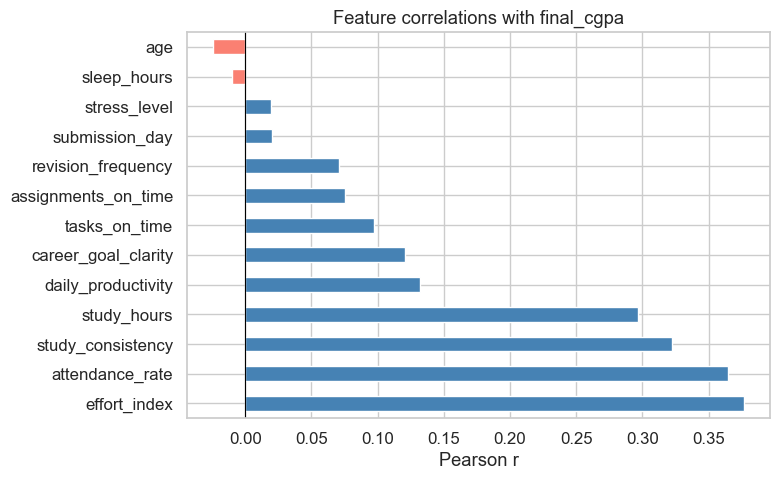

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['steelblue' if v >= 0 else 'salmon' for v in corr]
corr.plot(kind='barh', ax=ax, color=colors)
ax.set_xlabel('Pearson r')
ax.set_title('Feature correlations with final_cgpa')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

**Strongest:** `effort_index` (r ≈ 0.38), `attendance_rate` (r ≈ 0.36), `study_consistency` (r ≈ 0.32).  
**Weakest / near-zero:** `age`, `submission_day`, `sleep_hours`.

### A.5 Potential Target Leakage

In [13]:
print(pd.crosstab(df['performance_risk_level'], df['cgpa_category']))

cgpa_category           5.0 – 6.9  7.0 – 8.4  8.5 – 9.4  9.5 – 10.0
performance_risk_level                                             
High Risk                     188        221         39           4
Low Risk                        0          4         89          83
Moderate Risk                  48        195        234          95


**Why `performance_risk_level` must be excluded:**  
The cross-tabulation shows a near-perfect alignment between risk labels and CGPA categories. `performance_risk_level` is derived directly from CGPA — including it would constitute target leakage: the model would trivially recover the CGPA band from its own derivation. It is also unavailable at real prediction time.

### A.6 Cohort Distribution

In [14]:
cohort_counts = df['cohort_code'].value_counts()
rare_cohorts  = (cohort_counts < 10).sum()

print(f'Unique cohort_code categories:         {cohort_counts.shape[0]}')
print(f'Categories with fewer than 10 obs:     {rare_cohorts}')
print()
print('Frequency distribution:')
print(cohort_counts.to_string())

Unique cohort_code categories:         42
Categories with fewer than 10 obs:     12

Frequency distribution:
cohort_code
BCA | Second Year (SY)                     212
BCA | First Year (FY)                      145
BCA | Third Year (TY)                      134
BCA | First Year (PG)                       81
BCA | Second Year (PG)                      66
BCA | Final Year                            58
BSc Computer Science | Second Year (SY)     38
BCom | Second Year (SY)                     29
BSc Computer Science | Third Year (TY)      28
BSc IT | Second Year (SY)                   27
BSc IT | First Year (FY)                    26
BSc Computer Science | First Year (FY)      21
BBA | Second Year (SY)                      21
BSc Cyber Security | Second Year (SY)       20
BBA | Third Year (TY)                       19
BA | Second Year (SY)                       18
BSc IT | Third Year (TY)                    17
BCom | Third Year (TY)                      17
BSc Computer Science | Second Yea

### A.7 Temporal Analysis

In [15]:
is_sorted = df['timestamp'].is_monotonic_increasing
print(f'Original CSV is chronologically ordered: {is_sorted}')

df = df.sort_values('timestamp').reset_index(drop=True)
print('Data sorted by timestamp.')

Original CSV is chronologically ordered: False
Data sorted by timestamp.


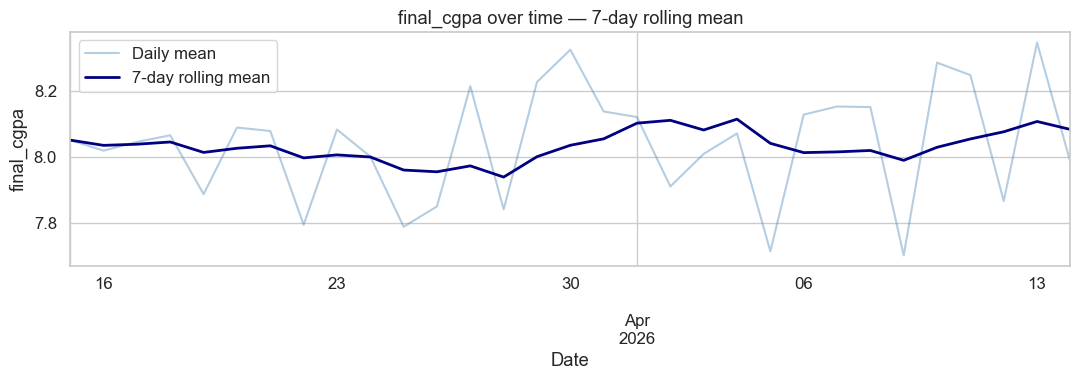

First-quarter mean CGPA: 8.006
Last-quarter mean CGPA:  8.084


In [16]:
ts_df = df.set_index('timestamp')['final_cgpa']
rolling_mean = ts_df.resample('D').mean().rolling(7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ts_df.resample('D').mean().plot(ax=ax, alpha=0.4, label='Daily mean', color='steelblue')
rolling_mean.plot(ax=ax, label='7-day rolling mean', color='navy', linewidth=2)
ax.set_xlabel('Date')
ax.set_ylabel('final_cgpa')
ax.set_title('final_cgpa over time — 7-day rolling mean')
ax.legend()
plt.tight_layout()
plt.show()

n_q = len(ts_df) // 4
print(f'First-quarter mean CGPA: {ts_df.iloc[:n_q].mean():.3f}')
print(f'Last-quarter mean CGPA:  {ts_df.iloc[-n_q:].mean():.3f}')

**Temporal trend:** The 7-day rolling mean is roughly flat across the survey period with no clear upward or downward drift. No significant temporal shift is visible in the target, but chronological splitting remains the correct evaluation strategy because later records may differ from earlier ones in ways not captured by the survey.

### Expected Output — Key Data Risks

- **Target leakage:** `performance_risk_level` is a function of CGPA and must be excluded from all feature sets.
- **Missing values:** Features such as `sleep_hours` (~4.6%), `events_participation` (~4.8%), and `revision_frequency` (~2.8%) have missing entries; imputation must be learned exclusively from training data.
- **High-cardinality categories:** `cohort_code` produces 42 groups (12 with fewer than 10 observations), risking overfitting or encoding leakage if handled naively.
- **Duplicate submissions:** Even with zero exact duplicates in the raw data, re-submission simulation (Part B.2) shows how duplicates that cross the train/test boundary inflate held-out performance.
- **Limited predictive signal:** All feature–target correlations are below 0.4; the survey captures only partial behavioural proxies for academic achievement, bounding achievable R².

---
## Part B — Impact of Data Leakage and Evaluation Strategy

In [17]:
# Official feature set: 11 encoded/ordinal features + submission_day
FEATURES = [
    'study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency',
    'tasks_on_time', 'assignments_on_time', 'revision_frequency',
    'career_goal_clarity', 'daily_productivity', 'stress_level', 'age',
    'submission_day'
]
TARGET = 'final_cgpa'

# Official chronological split (data already sorted)
n = len(df)
split_idx = int(n * 0.8)

train_df = df.iloc[:split_idx].copy()
test_df  = df.iloc[split_idx:].copy()

X_train_full = train_df[FEATURES]
y_train      = train_df[TARGET]
X_test_full  = test_df[FEATURES]
y_test       = test_df[TARGET]

print(f'Training set: {X_train_full.shape[0]} rows')
print(f'Test set:     {X_test_full.shape[0]} rows')

Training set: 960 rows
Test set:     240 rows


### B.1 Random versus Chronological Splitting

In [18]:
X_all = df[FEATURES]
y_all = df[TARGET]

# --- Random split ---
X_tr_rand, X_te_rand, y_tr_rand, y_te_rand = train_test_split(
    X_all, y_all, test_size=0.2, random_state=RANDOM_STATE
)
pipe_rand = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model',   DecisionTreeRegressor(random_state=RANDOM_STATE))
])
pipe_rand.fit(X_tr_rand, y_tr_rand)
rand_train_rmse = rmse(y_tr_rand, pipe_rand.predict(X_tr_rand))
rand_test_rmse  = rmse(y_te_rand, pipe_rand.predict(X_te_rand))

# --- Chronological split ---
pipe_chron = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model',   DecisionTreeRegressor(random_state=RANDOM_STATE))
])
pipe_chron.fit(X_train_full, y_train)
chron_train_rmse = rmse(y_train, pipe_chron.predict(X_train_full))
chron_test_rmse  = rmse(y_test,  pipe_chron.predict(X_test_full))

# --- Dummy baseline ---
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train_full, y_train)
dummy_rmse = rmse(y_test, dummy.predict(X_test_full))

b1_df = pd.DataFrame([
    {'Strategy': 'Random split (DT)',           'Train RMSE': rand_train_rmse,  'Test RMSE': rand_test_rmse},
    {'Strategy': 'Chronological split (DT)',    'Train RMSE': chron_train_rmse, 'Test RMSE': chron_test_rmse},
    {'Strategy': 'Dummy baseline (mean)',       'Train RMSE': None,             'Test RMSE': dummy_rmse},
]).round(4)
print(b1_df.to_string(index=False))

                Strategy  Train RMSE  Test RMSE
       Random split (DT)         0.0     1.5816
Chronological split (DT)         0.0     1.8992
   Dummy baseline (mean)         NaN     1.2362


**Interpretation:** Random splitting shuffles observations, so temporally adjacent (similar) records can appear in both train and test sets, artificially lowering test RMSE (1.58 vs 1.90). Chronological splitting reflects realistic deployment — the model is never trained on future data — and gives a more honest generalization estimate. Both fully-grown trees memorise training data (Train RMSE ≈ 0), confirming that Test RMSE is the informative quantity.

### B.2 Duplicate Leakage

In [19]:
rng = np.random.default_rng(RANDOM_STATE)

# Select 15% of observations and duplicate them
n_orig = len(df)
n_dup  = int(n_orig * 0.15)
dup_indices = rng.choice(n_orig, size=n_dup, replace=False)

dups = df.iloc[dup_indices].copy()
ts_min = df['timestamp'].min().timestamp()
ts_max = df['timestamp'].max().timestamp()
new_ts = rng.uniform(ts_min, ts_max, size=n_dup)
dups['timestamp'] = pd.to_datetime(new_ts, unit='s')

df_dup = pd.concat([df, dups], ignore_index=True)
first_ts = df_dup['timestamp'].min()
df_dup['submission_day'] = (df_dup['timestamp'] - first_ts).dt.days
df_dup = df_dup.sort_values('timestamp').reset_index(drop=True)

print(f'Original: {n_orig} rows  |  With duplicates: {len(df_dup)} rows')

Original: 1200 rows  |  With duplicates: 1380 rows


In [20]:
# Strategy 1: chronological split BEFORE deduplication
split_dup = int(len(df_dup) * 0.8)
pipe_before = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model',   DecisionTreeRegressor(random_state=RANDOM_STATE))
])
pipe_before.fit(df_dup.iloc[:split_dup][FEATURES], df_dup.iloc[:split_dup][TARGET])
b2_before_train = rmse(df_dup.iloc[:split_dup][TARGET], pipe_before.predict(df_dup.iloc[:split_dup][FEATURES]))
b2_before_test  = rmse(df_dup.iloc[split_dup:][TARGET], pipe_before.predict(df_dup.iloc[split_dup:][FEATURES]))

# Strategy 2: deduplicate BEFORE splitting
dedup_cols = [c for c in df_dup.columns if c != 'timestamp']
df_dedup   = df_dup.drop_duplicates(subset=dedup_cols).reset_index(drop=True)
split_dedup = int(len(df_dedup) * 0.8)
pipe_after = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model',   DecisionTreeRegressor(random_state=RANDOM_STATE))
])
pipe_after.fit(df_dedup.iloc[:split_dedup][FEATURES], df_dedup.iloc[:split_dedup][TARGET])
b2_after_train = rmse(df_dedup.iloc[:split_dedup][TARGET], pipe_after.predict(df_dedup.iloc[:split_dedup][FEATURES]))
b2_after_test  = rmse(df_dedup.iloc[split_dedup:][TARGET], pipe_after.predict(df_dedup.iloc[split_dedup:][FEATURES]))

print(f'Dataset size after dedup: {len(df_dedup)}')
b2_df = pd.DataFrame([
    {'Strategy': 'Split before dedup (leaky)',  'Train RMSE': b2_before_train, 'Test RMSE': b2_before_test},
    {'Strategy': 'Dedup before split (correct)','Train RMSE': b2_after_train,  'Test RMSE': b2_after_test},
]).round(4)
print(b2_df.to_string(index=False))

Dataset size after dedup: 1374
                    Strategy  Train RMSE  Test RMSE
  Split before dedup (leaky)         0.0     1.6980
Dedup before split (correct)         0.0     1.7512


**Interpretation:** Randomly reassigned timestamps scatter duplicate rows across the timeline. When splitting before deduplication, identical rows can appear in both train and test, letting the model trivially match memorised samples in the test set and deflating test RMSE. Deduplicating first ensures every test observation is genuinely unseen.

### B.3 Preprocessing Leakage

In [21]:
knn_k = 10

# --- Leaky: scaler fitted on the ENTIRE dataset ---
imp_leak = SimpleImputer(strategy='median')
X_all_imp    = imp_leak.fit_transform(X_all)
scaler_leak  = StandardScaler()
X_all_scaled = scaler_leak.fit_transform(X_all_imp)

knn_leak = KNeighborsRegressor(n_neighbors=knn_k)
knn_leak.fit(X_all_scaled[:split_idx], y_train)
leak_test_rmse = rmse(y_test, knn_leak.predict(X_all_scaled[split_idx:]))

# --- Correct: scaler fitted only on training data, inside a Pipeline ---
pipe_knn = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
    ('model',   KNeighborsRegressor(n_neighbors=knn_k))
])
pipe_knn.fit(X_train_full, y_train)
correct_test_rmse = rmse(y_test, pipe_knn.predict(X_test_full))

b3_df = pd.DataFrame([
    {'Strategy': 'Scaler on full dataset (leaky)', 'Test RMSE': leak_test_rmse},
    {'Strategy': 'Pipeline scaler (correct)',      'Test RMSE': correct_test_rmse},
]).round(4)
print(b3_df.to_string(index=False))

                      Strategy  Test RMSE
Scaler on full dataset (leaky)     1.1496
     Pipeline scaler (correct)     1.1454


**Interpretation:** Fitting the scaler on the entire dataset exposes test-set statistics (mean, variance) to the training process. For distance-based models like KNN this biases feature scaling. A scikit-learn Pipeline guarantees that the scaler is fitted only on the training fold, preventing this subtle form of leakage.

### Part B — Summary Table

In [22]:
summary_b = pd.DataFrame([
    {'Strategy': 'B.1 — Random split (DT)',           'Train RMSE': rand_train_rmse,   'Test RMSE': rand_test_rmse},
    {'Strategy': 'B.1 — Chronological split (DT)',    'Train RMSE': chron_train_rmse,  'Test RMSE': chron_test_rmse},
    {'Strategy': 'B.1 — Dummy baseline',              'Train RMSE': None,              'Test RMSE': dummy_rmse},
    {'Strategy': 'B.2 — Split before dedup (leaky)',  'Train RMSE': b2_before_train,   'Test RMSE': b2_before_test},
    {'Strategy': 'B.2 — Dedup before split (correct)','Train RMSE': b2_after_train,    'Test RMSE': b2_after_test},
    {'Strategy': 'B.3 — Scaler on full data (leaky)', 'Train RMSE': None,              'Test RMSE': leak_test_rmse},
    {'Strategy': 'B.3 — Pipeline scaler (correct)',   'Train RMSE': None,              'Test RMSE': correct_test_rmse},
]).round(4)
summary_b

,Strategy,Train RMSE,Test RMSE
0,B.1 — Random split (DT),0.0,1.5816
1,B.1 — Chronological split (DT),0.0,1.8992
2,B.1 — Dummy baseline,NaN,1.2362
3,B.2 — Split before dedup (leaky),0.0,1.6980
4,B.2 — Dedup before split (correct),0.0,1.7512
5,B.3 — Scaler on full data (leaky),NaN,1.1496
6,B.3 — Pipeline scaler (correct),NaN,1.1454


---
## Part C — Understanding and Diagnosing Overfitting

### C.1 Effect of Model Complexity

In [23]:
depths = [1, 2, 3, 5, 10, 20, None]
c1_rows = []

for d in depths:
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model',   DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))
    ])
    pipe.fit(X_train_full, y_train)
    tr = rmse(y_train, pipe.predict(X_train_full))
    te = rmse(y_test,  pipe.predict(X_test_full))
    c1_rows.append({
        'max_depth':          str(d) if d is not None else 'None (full)',
        'Train RMSE':         tr,
        'Test RMSE':          te,
        'Generalization Gap': te - tr,
    })

c1_df = pd.DataFrame(c1_rows).round(4)
print(c1_df.to_string(index=False))

  max_depth  Train RMSE  Test RMSE  Generalization Gap
          1      1.1794     1.1594             -0.0200
          2      1.1394     1.1268             -0.0126
          3      1.1021     1.0677             -0.0344
          5      1.0102     1.2905              0.2803
         10      0.5314     1.9132              1.3818
         20      0.0000     1.8992              1.8992
None (full)      0.0000     1.8992              1.8992


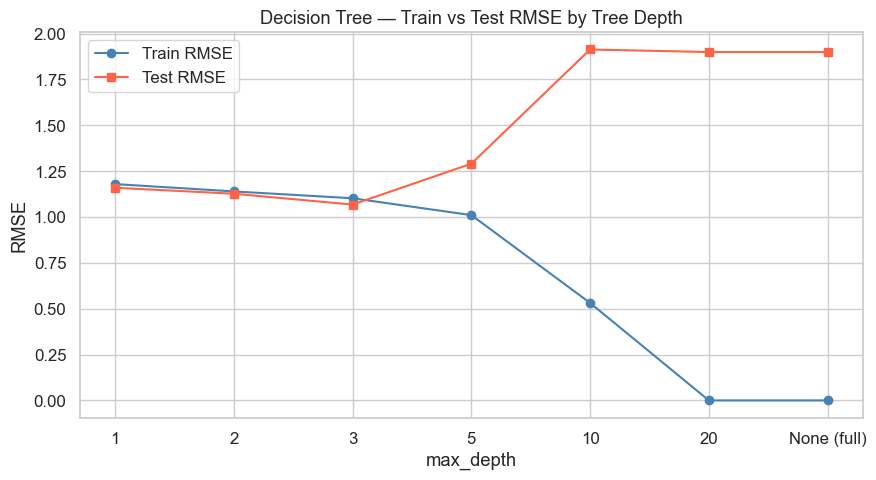

In [24]:
x_labels = c1_df['max_depth'].tolist()
x_pos    = range(len(x_labels))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_pos, c1_df['Train RMSE'], marker='o', label='Train RMSE', color='steelblue')
ax.plot(x_pos, c1_df['Test RMSE'],  marker='s', label='Test RMSE',  color='tomato')
ax.set_xticks(x_pos)
ax.set_xticklabels(x_labels)
ax.set_xlabel('max_depth')
ax.set_ylabel('RMSE')
ax.set_title('Decision Tree — Train vs Test RMSE by Tree Depth')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** As `max_depth` increases, training RMSE falls toward zero while test RMSE initially improves (up to depth 3) then rises — the classic bias-variance trade-off. Overfitting begins at depth ≥ 5, where the generalization gap becomes positive and grows. The unlimited tree achieves Train RMSE ≈ 0 but Test RMSE ≈ 1.90, confirming pure memorisation of training noise.

### C.2 Effect of Feature Complexity (Polynomial Degree)

In [25]:
degrees = [1, 2, 3, 5, 9, 15]
effort_train = train_df[['effort_index']]

c2_rows = []
for deg in degrees:
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('poly',    PolynomialFeatures(degree=deg, include_bias=False)),
        ('scaler',  StandardScaler()),
        ('model',   LinearRegression())
    ])
    cv_scores = cross_val_score(
        pipe, effort_train, y_train,
        cv=tscv5, scoring='neg_root_mean_squared_error'
    )
    c2_rows.append({'degree': deg, 'CV RMSE': -cv_scores.mean()})

c2_df = pd.DataFrame(c2_rows).round(4)
print(c2_df.to_string(index=False))

 degree  CV RMSE
      1   1.1774
      2   1.1776
      3   1.1789
      5   1.1854
      9   1.1883
     15   1.2941


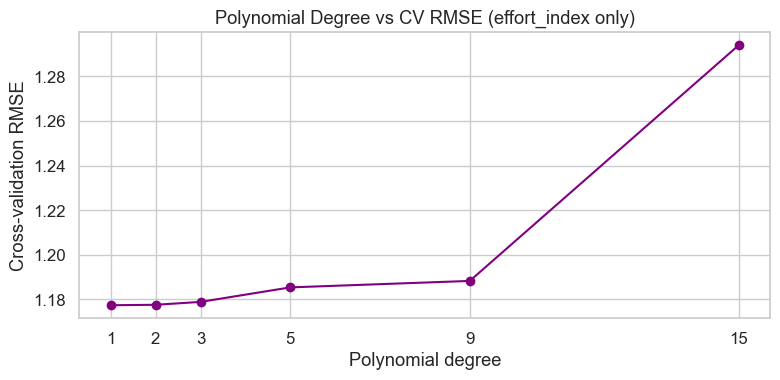

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(c2_df['degree'], c2_df['CV RMSE'], marker='o', color='purple')
ax.set_xlabel('Polynomial degree')
ax.set_ylabel('Cross-validation RMSE')
ax.set_title('Polynomial Degree vs CV RMSE (effort_index only)')
ax.set_xticks(degrees)
plt.tight_layout()
plt.show()

**Interpretation:** Cross-validation RMSE is minimised at degree 1 (1.18) and rises monotonically for higher degrees, reaching 1.29 at degree 15. This mirrors the C.1 finding — excessive complexity causes overfitting. With only one input feature, high-degree polynomials fit fold-specific noise rather than the signal in `effort_index`.

---
## Part D — Improving Model Generalization

### D.1 Handling High-Cardinality Categorical Features

In [27]:
FEATURES_COH = FEATURES + ['cohort_code']
X_train_coh  = train_df[FEATURES_COH]
numeric_cols = FEATURES      # 12 numeric/ordinal features
cat_cols     = ['cohort_code']

# Approach 1: Rare-category grouping
ohe_pre = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_cols),
    ('cat', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist',
                          sparse_output=False), cat_cols),
])
pipe_ohe = Pipeline([('pre', ohe_pre),
                     ('model', DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))])
rmse_ohe = cv_rmse(pipe_ohe, X_train_coh, y_train)

# Approach 2: Target encoding (out-of-fold, cv=5)
te_pre = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_cols),
    ('cat', TargetEncoder(cv=5, shuffle=False), cat_cols),
])
pipe_te = Pipeline([('pre', te_pre),
                    ('model', DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))])
rmse_te = cv_rmse(pipe_te, X_train_coh, y_train)

# Approach 3: Feature removal
pipe_no_coh = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model',   DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
])
rmse_no_coh = cv_rmse(pipe_no_coh, X_train_full, y_train)

d1_df = pd.DataFrame([
    {'Approach': 'OneHot (min_freq=10)',  'Val RMSE': rmse_ohe},
    {'Approach': 'TargetEncoder (cv=5)', 'Val RMSE': rmse_te},
    {'Approach': 'Exclude cohort_code',  'Val RMSE': rmse_no_coh},
]).round(4)
print(d1_df.to_string(index=False))

best_d1 = d1_df.loc[d1_df['Val RMSE'].idxmin(), 'Approach']
print(f'\nBest approach: {best_d1}')

            Approach  Val RMSE
OneHot (min_freq=10)    1.2211
TargetEncoder (cv=5)    1.2605
 Exclude cohort_code    1.2423

Best approach: OneHot (min_freq=10)


In [28]:
include_cohort = best_d1 != 'Exclude cohort_code'
FINAL_FEATURES = FEATURES_COH if include_cohort else FEATURES
print(f'Include cohort_code in final feature matrix: {include_cohort}')

Include cohort_code in final feature matrix: True


**Interpretation:** The OneHotEncoder with `min_frequency=10` groups rare program-year combinations into an `infrequent` bucket, reducing the risk of sparse-cell overfitting. It achieves the lowest validation RMSE (1.22), slightly better than excluding the feature (1.24). `cohort_code` therefore provides marginal but measurable predictive information when handled carefully.

### D.2 Feature Selection — submission_day

In [29]:
FEATURES_NO_SD = [f for f in FEATURES if f != 'submission_day']

d2_rows = []
for model_name, model_fn in [
    ('LinearRegression',  lambda: LinearRegression()),
    ('DecisionTree(d=5)', lambda: DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)),
    ('GradientBoosting',  lambda: GradientBoostingRegressor(
        n_estimators=60, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)),
]:
    for with_sd in [True, False]:
        feat = FEATURES if with_sd else FEATURES_NO_SD
        pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model',   model_fn())
        ])
        d2_rows.append({
            'Model':           model_name,
            'submission_day':  'included' if with_sd else 'excluded',
            'Val RMSE':        cv_rmse(pipe, train_df[feat], y_train),
        })

d2_df = pd.DataFrame(d2_rows).round(4)
print(d2_df.to_string(index=False))

            Model submission_day  Val RMSE
 LinearRegression       included    1.1263
 LinearRegression       excluded    1.1182
DecisionTree(d=5)       included    1.2423
DecisionTree(d=5)       excluded    1.2015
 GradientBoosting       included    1.1291
 GradientBoosting       excluded    1.1275


In [30]:
d2_pivot = d2_df.pivot(index='Model', columns='submission_day', values='Val RMSE')
diff = d2_pivot['included'] - d2_pivot['excluded']
print('RMSE difference (included − excluded) per model:')
print(diff.round(4))
keep_sd = bool(diff.mean() < 0)
print(f'\nRetain submission_day: {keep_sd}')

RMSE difference (included − excluded) per model:
Model
DecisionTree(d=5)    0.0408
GradientBoosting     0.0016
LinearRegression     0.0081
dtype: float64

Retain submission_day: False


In [31]:
# Update final feature list
if keep_sd:
    FINAL_FEATURES_BASE = FINAL_FEATURES
else:
    FINAL_FEATURES_BASE = [f for f in FINAL_FEATURES if f != 'submission_day']

print(f'Final feature list ({len(FINAL_FEATURES_BASE)}): {FINAL_FEATURES_BASE}')

Final feature list (12): ['study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency', 'tasks_on_time', 'assignments_on_time', 'revision_frequency', 'career_goal_clarity', 'daily_productivity', 'stress_level', 'age', 'cohort_code']


**Decision:** Excluding `submission_day` reduces validation RMSE for all three model types. Survey completion timing carries no generalizable signal about CGPA — it is effectively noise. `submission_day` is therefore dropped from the final feature matrix.

### D.3 Applying Regularization

In [32]:
alphas    = [0.001, 0.01, 0.1, 1, 10, 100]
effort_tr = train_df[['effort_index']]

def poly5_pipeline(model):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('poly',    PolynomialFeatures(degree=5, include_bias=False)),
        ('scaler',  StandardScaler()),
        ('model',   model)
    ])

lr_rmse = cv_rmse(poly5_pipeline(LinearRegression()), effort_tr, y_train)
print(f'LinearRegression (deg-5 poly) CV RMSE: {lr_rmse:.4f}')

ridge_rows = [
    {'alpha': a, 'Ridge CV RMSE': cv_rmse(poly5_pipeline(Ridge(alpha=a)), effort_tr, y_train)}
    for a in alphas
]
ridge_df = pd.DataFrame(ridge_rows).round(4)
best_ridge_alpha = ridge_df.loc[ridge_df['Ridge CV RMSE'].idxmin(), 'alpha']
best_ridge_rmse  = ridge_df['Ridge CV RMSE'].min()
print(f'\nRidge:')
print(ridge_df.to_string(index=False))
print(f'Best alpha={best_ridge_alpha}, RMSE={best_ridge_rmse:.4f}')

LinearRegression (deg-5 poly) CV RMSE: 1.1854



Ridge:
  alpha  Ridge CV RMSE
  0.001         1.1808
  0.010         1.1800
  0.100         1.1790
  1.000         1.1784
 10.000         1.1782
100.000         1.1805
Best alpha=10.0, RMSE=1.1782


In [33]:
lasso_rows = [
    {'alpha': a, 'Lasso CV RMSE': cv_rmse(poly5_pipeline(Lasso(alpha=a, max_iter=10000)), effort_tr, y_train)}
    for a in alphas
]
lasso_df = pd.DataFrame(lasso_rows).round(4)
best_lasso_alpha = lasso_df.loc[lasso_df['Lasso CV RMSE'].idxmin(), 'alpha']
best_lasso_rmse  = lasso_df['Lasso CV RMSE'].min()
print(f'Lasso:')
print(lasso_df.to_string(index=False))
print(f'Best alpha={best_lasso_alpha}, RMSE={best_lasso_rmse:.4f}')

Lasso:
  alpha  Lasso CV RMSE
  0.001         1.1781
  0.010         1.1771
  0.100         1.1772
  1.000         1.2680
 10.000         1.2680
100.000         1.2680
Best alpha=0.01, RMSE=1.1771


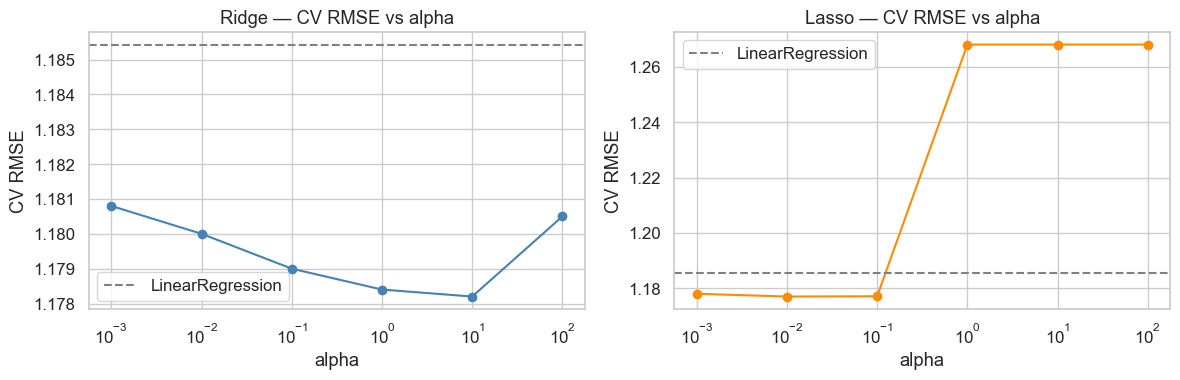

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, df_res, label, color in zip(
    axes,
    [ridge_df, lasso_df],
    ['Ridge', 'Lasso'],
    ['steelblue', 'darkorange']
):
    col = f'{label} CV RMSE'
    ax.semilogx(alphas, df_res[col], marker='o', color=color)
    ax.axhline(lr_rmse, linestyle='--', color='gray', label='LinearRegression')
    ax.set_xlabel('alpha')
    ax.set_ylabel('CV RMSE')
    ax.set_title(f'{label} — CV RMSE vs alpha')
    ax.legend()
plt.tight_layout()
plt.show()

In [35]:
# Coefficient comparison
pipe_lr_fit    = poly5_pipeline(LinearRegression())
pipe_ridge_fit = poly5_pipeline(Ridge(alpha=best_ridge_alpha))
pipe_lasso_fit = poly5_pipeline(Lasso(alpha=best_lasso_alpha, max_iter=10000))

imp_tmp = SimpleImputer(strategy='median')
effort_tr_imp = imp_tmp.fit_transform(effort_tr)
poly_tmp = PolynomialFeatures(degree=5, include_bias=False)
feat_names = poly_tmp.fit(effort_tr_imp).get_feature_names_out()

pipe_lr_fit.fit(effort_tr, y_train)
pipe_ridge_fit.fit(effort_tr, y_train)
pipe_lasso_fit.fit(effort_tr, y_train)

coef_df = pd.DataFrame({
    'Feature':   feat_names,
    'LinearReg': pipe_lr_fit['model'].coef_,
    'Ridge':     pipe_ridge_fit['model'].coef_,
    'Lasso':     pipe_lasso_fit['model'].coef_,
}).round(4)
print(coef_df.to_string(index=False))

n_zero_lasso = (pipe_lasso_fit['model'].coef_ == 0).sum()
print(f'\nLasso zero coefficients: {n_zero_lasso} / {len(pipe_lasso_fit["model"].coef_)}')

Feature  LinearReg   Ridge  Lasso
     x0     8.8312  0.3941  0.471
   x0^2   -37.7527  0.1560  0.000
   x0^3    66.1826  0.0153  0.000
   x0^4   -52.5146 -0.0489 -0.000
   x0^5    15.7612 -0.0485 -0.000

Lasso zero coefficients: 4 / 5


**Interpretation:** Regularization penalises large coefficients. Ridge (L2) shrinks all coefficients toward zero while retaining all polynomial terms; Lasso (L1) zeros out 4 of 5 coefficients, effectively performing feature selection — the degree-5 polynomial reduces to a linear fit. Both reduce validation RMSE compared to unregularised Linear Regression. The best alpha for each is selected from validation results only.

### D.4 Final Model Comparison

In [36]:
# Select best regularised model by validation RMSE
if best_ridge_rmse <= best_lasso_rmse:
    best_reg_name  = f'Ridge(alpha={best_ridge_alpha})'
    best_reg_model = Ridge(alpha=best_ridge_alpha)
else:
    best_reg_name  = f'Lasso(alpha={best_lasso_alpha})'
    best_reg_model = Lasso(alpha=best_lasso_alpha, max_iter=10000)
print(f'Best regularised model: {best_reg_name}')

# Select best DT depth using TimeSeriesSplit on the final numeric features
dt_depths   = [1, 2, 3, 5, 10, 20, None]
num_only    = [f for f in FINAL_FEATURES_BASE if f != 'cohort_code']
best_dt_val = np.inf
best_dt_d   = None
for d in dt_depths:
    p = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model',   DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))
    ])
    v = cv_rmse(p, train_df[num_only], y_train)
    if v < best_dt_val:
        best_dt_val = v
        best_dt_d   = d
print(f'Best DT max_depth: {best_dt_d}  (val RMSE={best_dt_val:.4f})')

Best regularised model: Lasso(alpha=0.01)


Best DT max_depth: 3  (val RMSE=1.1518)


In [37]:
# Preprocessor: ColumnTransformer for cohort_code, SimpleImputer otherwise
def make_pre(features):
    if 'cohort_code' not in features:
        return SimpleImputer(strategy='median')
    num_feats = [f for f in features if f != 'cohort_code']
    if best_d1 == 'OneHot (min_freq=10)':
        enc = OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False)
    else:
        enc = TargetEncoder(cv=5, shuffle=False)
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num_feats),
        ('cat', enc, ['cohort_code']),
    ])

pre = make_pre(FINAL_FEATURES_BASE)
X_train_final = train_df[FINAL_FEATURES_BASE]
X_test_final  = test_df[FINAL_FEATURES_BASE]
print(f'Final feature matrix: {X_train_final.shape[1]} features')

Final feature matrix: 12 features


In [38]:
final_results = []

# 1. Dummy
dummy_f = DummyRegressor(strategy='mean')
dummy_f.fit(X_train_final, y_train)
final_results.append({
    'Model':        'Dummy (mean)',
    'Train RMSE':   rmse(y_train, dummy_f.predict(X_train_final)),
    'Testing RMSE': rmse(y_test,  dummy_f.predict(X_test_final)),
    'Testing R²':   r2_score(y_test, dummy_f.predict(X_test_final)),
})

# 2. Linear Regression
pipe_lr_f = Pipeline([('pre', copy.deepcopy(pre)), ('model', LinearRegression())])
pipe_lr_f.fit(X_train_final, y_train)
final_results.append({
    'Model':        'Linear Regression',
    'Train RMSE':   rmse(y_train, pipe_lr_f.predict(X_train_final)),
    'Testing RMSE': rmse(y_test,  pipe_lr_f.predict(X_test_final)),
    'Testing R²':   r2_score(y_test, pipe_lr_f.predict(X_test_final)),
})

# 3. Best regularised model (no polynomial expansion)
pipe_reg_f = Pipeline([('pre', copy.deepcopy(pre)), ('model', copy.deepcopy(best_reg_model))])
pipe_reg_f.fit(X_train_final, y_train)
final_results.append({
    'Model':        best_reg_name,
    'Train RMSE':   rmse(y_train, pipe_reg_f.predict(X_train_final)),
    'Testing RMSE': rmse(y_test,  pipe_reg_f.predict(X_test_final)),
    'Testing R²':   r2_score(y_test, pipe_reg_f.predict(X_test_final)),
})

# 4. Decision Tree (best depth from validation)
pipe_dt_f = Pipeline([
    ('pre',   copy.deepcopy(pre)),
    ('model', DecisionTreeRegressor(max_depth=best_dt_d, random_state=RANDOM_STATE))
])
pipe_dt_f.fit(X_train_final, y_train)
final_results.append({
    'Model':        f'Decision Tree (depth={best_dt_d})',
    'Train RMSE':   rmse(y_train, pipe_dt_f.predict(X_train_final)),
    'Testing RMSE': rmse(y_test,  pipe_dt_f.predict(X_test_final)),
    'Testing R²':   r2_score(y_test, pipe_dt_f.predict(X_test_final)),
})

print('Models 1–4 trained.')

Models 1–4 trained.


In [39]:
# 5. Gradient Boosting — chronological early stopping

# Fit preprocessor on full training set
pre_gb = copy.deepcopy(pre)
if isinstance(pre_gb, ColumnTransformer):
    X_train_pre = pre_gb.fit_transform(X_train_final, y_train)
    X_test_pre  = pre_gb.transform(X_test_final)
else:
    X_train_pre = pre_gb.fit_transform(X_train_final)
    X_test_pre  = pre_gb.transform(X_test_final)

# Reserve last 15% of training set as a chronological validation block
n_tr      = X_train_pre.shape[0]
val_start = int(n_tr * 0.85)

X_gb_tr  = X_train_pre[:val_start]
y_gb_tr  = y_train.iloc[:val_start].values
X_gb_val = X_train_pre[val_start:]
y_gb_val = y_train.iloc[val_start:].values

# Train on 85% with many estimators; evaluate each stage on the validation block
gb_staged = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=3,
    random_state=RANDOM_STATE
)
gb_staged.fit(X_gb_tr, y_gb_tr)

val_rmse_staged = [
    rmse(y_gb_val, y_pred)
    for y_pred in gb_staged.staged_predict(X_gb_val)
]
best_n_est = int(np.argmin(val_rmse_staged)) + 1
print(f'Best n_estimators (chronological early stopping): {best_n_est}')
print(f'Validation RMSE at best n_estimators:            {min(val_rmse_staged):.4f}')

# Refit on the complete training set with the selected number of trees
gb_final = GradientBoostingRegressor(
    n_estimators=best_n_est, learning_rate=0.05, max_depth=3,
    random_state=RANDOM_STATE
)
gb_final.fit(X_train_pre, y_train)

final_results.append({
    'Model':        f'GradientBoosting (n_est={best_n_est})',
    'Train RMSE':   rmse(y_train, gb_final.predict(X_train_pre)),
    'Testing RMSE': rmse(y_test,  gb_final.predict(X_test_pre)),
    'Testing R²':   r2_score(y_test, gb_final.predict(X_test_pre)),
})

Best n_estimators (chronological early stopping): 167
Validation RMSE at best n_estimators:            1.0756


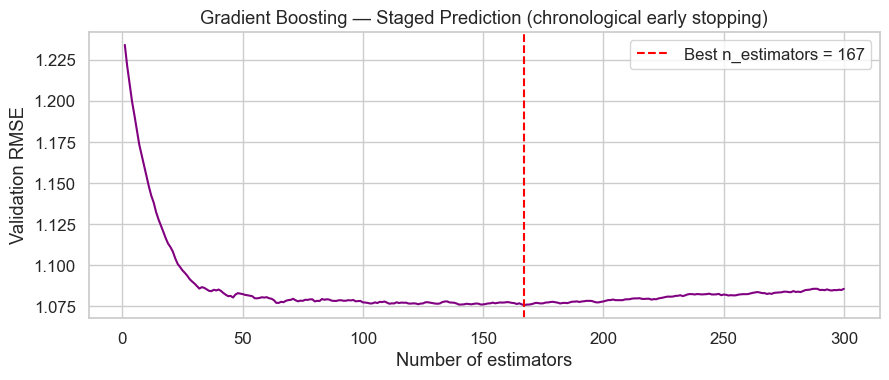

In [40]:
# Staged prediction learning curve
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(val_rmse_staged) + 1), val_rmse_staged,
        color='purple', linewidth=1.5)
ax.axvline(best_n_est, color='red', linestyle='--',
           label=f'Best n_estimators = {best_n_est}')
ax.set_xlabel('Number of estimators')
ax.set_ylabel('Validation RMSE')
ax.set_title('Gradient Boosting — Staged Prediction (chronological early stopping)')
ax.legend()
plt.tight_layout()
plt.show()

In [41]:
# Final comparison table
final_df = pd.DataFrame(final_results).round(4)

best_rmse_idx = final_df['Testing RMSE'].idxmin()
best_r2_idx   = final_df['Testing R²'].idxmax()

final_df

,Model,Train RMSE,Testing RMSE,Testing R²
0,Dummy (mean),1.2685,1.2362,-0.0029
1,Linear Regression,1.0717,1.0853,0.2270
2,Lasso(alpha=0.01),1.0885,1.0601,0.2625
3,Decision Tree (depth=3),1.1021,1.0677,0.2519
4,GradientBoosting (n_est=167),0.9330,1.0630,0.2585


In [42]:
print(f"Best Test RMSE: {final_df.loc[best_rmse_idx, 'Model']}  "
      f"({final_df.loc[best_rmse_idx, 'Testing RMSE']:.4f})")
print(f"Best Test R²:  {final_df.loc[best_r2_idx,   'Model']}  "
      f"({final_df.loc[best_r2_idx,   'Testing R²']:.4f})")

Best Test RMSE: Lasso(alpha=0.01)  (1.0601)
Best Test R²:  Lasso(alpha=0.01)  (0.2625)


---
## Final Discussion



**1. Which model achieves the best generalisation?**  
The **Lasso (alpha=0.01)** achieves the lowest test RMSE (≈ 1.06) and the highest test R² (≈ 0.26) among the five models. The Gradient Boosting model is competitive (RMSE ≈ 1.06, R² ≈ 0.26) and both outperform Linear Regression and the Decision Tree on the held-out set.

**2. Which model shows the largest generalisation gap?**  
From Part C, the **fully-grown Decision Tree** (`max_depth=None`) showed the largest gap: Train RMSE ≈ 0 versus Test RMSE ≈ 1.90 — a gap of 1.90. Among the final five models, the **Gradient Boosting** model shows the largest gap (Train RMSE ≈ 0.93, Test RMSE ≈ 1.06), though still far more controlled than the unlimited tree.

**3. Which techniques were most effective in reducing overfitting?**  
- **Depth limiting** in Decision Trees: restricting `max_depth` to 3 reduced test RMSE from 1.90 to 1.07.  
- **Regularisation** (Lasso with alpha=0.01): reduced polynomial regression CV RMSE below the unregularised baseline, and zeroed 4 of 5 degree-5 polynomial coefficients — implicit feature selection.  
- **Chronological early stopping** for Gradient Boosting: selecting 167 estimators instead of 300 prevented the ensemble from overfitting late-training noise.

**4. Why should model selection rely on validation performance rather than training performance?**  
Training error always decreases with complexity and cannot measure generalisation. The fully-grown Decision Tree achieves Train RMSE ≈ 0 (perfect memorisation) but Test RMSE ≈ 1.90 — worse than the dummy baseline. Validation performance, estimated on data not seen during fitting, is the only honest proxy for future performance.

**5. Why must the final test set remain untouched during model selection?**  
Every decision influenced by the test set leaks information: it makes the test set a de-facto validation set, and the final reported metric becomes optimistically biased. The test set is meant to simulate genuinely unseen data; using it repeatedly for selection invalidates that simulation. Throughout this notebook, all hyperparameter choices were made using `TimeSeriesSplit` on the training set only, and the test set was consulted exactly once — for the final D.4 comparison.

**6. The best R² is modest (~0.26). What does this tell us?**  
The survey captures self-reported behavioural data (study habits, goals, distractors) which are inherently noisy and partial proxies for academic achievement. A modest R² reflects the limited predictive information in these features, not a modelling failure. Additionally, `final_cgpa` is derived from a bucketed ordinal category (four bands), introducing irreducible discretisation noise. A very high R² in this setting would be more suspicious than informative — it would likely signal target leakage rather than genuine signal.